## Analytics Firm Clients: Customer Reviews Analysis

### Part 1: Natural Language Processing (NLP)

In [1]:
! pip install seaborn
! pip install nltk

In [6]:
# Part 1: NLP 


# 1.1 Import libraries

# 1. Import libraries for data handling
import numpy as np
import pandas as pd

# 2. Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Import libraries for text cleaning
import re
import string
import html

# 4. Import libraries for Natural Language Processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.util import ngrams

# 5. Import Counter for word frequency analysis
from collections import Counter

# 6. Download required NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

# 7. Set random seed for reproducibility
np.random.seed(42)

# 8. Set visualization style
sns.set_theme(style='whitegrid')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\kevin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\kevin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kevin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\kevin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
# 1.2. Data loading and understanding

# 1. Load the dataset from the datasets folder
df = pd.read_csv("data/amazon_reviews_lab.csv")

print("Dataset loaded successfully!")

# 2. Display the shape of the dataset
print("Dataset shape:", df.shape)

# 3. Display the first few rows of the dataset
display(df.head())

Dataset loaded successfully!
Dataset shape: (997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [11]:
# 4. Inspect column names and data types
print("\nDataset Information:")
df.info()

# 5. Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 6. Check for duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 7. Examine the distribution of customer ratings
print("\nRating Distribution:")
print(df['rating'].value_counts().sort_index())

# 8. Examine the distribution of sentiment labels
print("\nSentiment Distribution:")
print(df['sentiment_label'].value_counts())

# 9. Generate summary statistics
display(df.describe(include='all'))


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           997 non-null    str    
 1   rating               997 non-null    int64  
 2   review_text          997 non-null    str    
 3   review_summary       997 non-null    str    
 4   review_time_raw      997 non-null    str    
 5   unix_review_time     997 non-null    float64
 6   timestamp            997 non-null    str    
 7   sentiment_label      997 non-null    str    
 8   review_length_words  997 non-null    int64  
dtypes: float64(1), int64(2), str(6)
memory usage: 70.2 KB

Missing Values:
product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64

Duplicate Records:
0

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
count,997,997.000000,997,997,997,9.970000e+02,997,997,997.000000
unique,40,NaN,997,938,722,NaN,722,3,NaN
top,0972683275,NaN,This film is definitely not for anyone who is ...,Works great,"09 18, 2013",NaN,2013-09-18,positive,NaN
freq,218,NaN,1,6,6,NaN,6,768,NaN
mean,NaN,4.129388,NaN,NaN,NaN,1.344766e+09,NaN,NaN,146.374122
std,NaN,1.280181,NaN,NaN,NaN,4.411420e+07,NaN,NaN,216.126770
min,NaN,1.000000,NaN,NaN,NaN,9.580896e+08,NaN,NaN,5.000000
25%,NaN,4.000000,NaN,NaN,NaN,1.311898e+09,NaN,NaN,32.000000
50%,NaN,5.000000,NaN,NaN,NaN,1.356048e+09,NaN,NaN,67.000000
75%,NaN,5.000000,NaN,NaN,NaN,1.379462e+09,NaN,NaN,165.000000


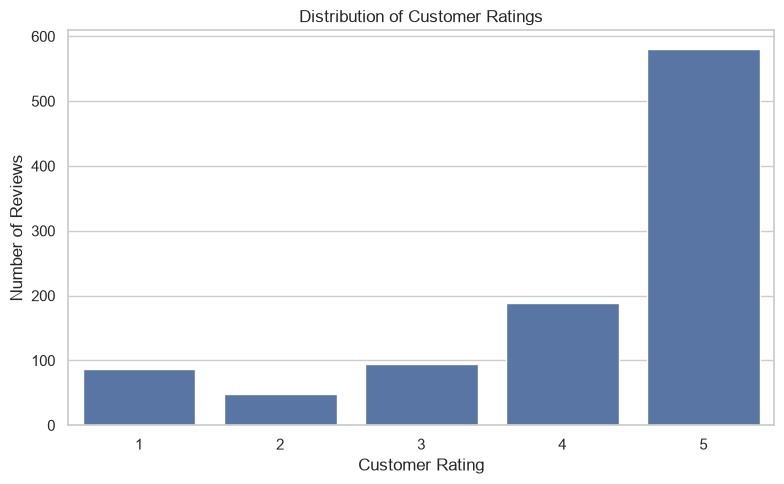

In [12]:
# 1.3. Exploratory Data Analysis - Rating Distribution

# 1. Create a figure
plt.figure(figsize=(8, 5))

# 2. Plot the frequency of each rating
sns.countplot(
    data=df,
    x='rating',
    order=sorted(df['rating'].dropna().unique())
)

# 3. Add descriptive labels
plt.title('Distribution of Customer Ratings')
plt.xlabel('Customer Rating')
plt.ylabel('Number of Reviews')

# 4. Display the visualization
plt.tight_layout()
plt.show()

In [13]:
# 1.4. Text Preprocessing Setup


# 1. Load common English stopwords
stop_words = set(stopwords.words('english'))

# 2. Initialize the WordNet lemmatizer
lemmatizer = WordNetLemmatizer()

# 3. Preserve negation words that may indicate sentiment
stop_words = stop_words - {
    'no', 'not', 'nor'
}

# 4. Inspect a few stopwords
print("Sample Stopwords:")
print(list(sorted(stop_words))[:20])

Sample Stopwords:
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']


In [14]:
# 1.5. Text Preprocessing Function

# Purpose:
# Create a reusable function that:
# 1. Converts text to lowercase
# 2. Removes URLs
# 3. Removes punctuation
# 4. Tokenizes the text
# 5. Keeps alphabetic tokens
# 6. Removes stopwords
# 7. Lemmatizes words
# 8. Returns cleaned tokens


def preprocess_text(text):

    # Step 1: Handle missing or non-text values
    if pd.isna(text):
        return []

    # Step 2: Convert text to lowercase
    text = str(text).lower()

    # Step 3: Decode HTML entities
    text = html.unescape(text)

    # Step 4: Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Step 5: Remove punctuation
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Step 6: Tokenize the text into individual words
    tokens = word_tokenize(text)

    # Step 7: Keep alphabetic tokens only
    tokens = [
        word for word in tokens
        if word.isalpha()
    ]

    # Step 8: Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Step 9: Lemmatize the remaining words
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Step 10: Return cleaned tokens
    return tokens


# Test the preprocessing function
sample_review = df['review_text'].dropna().iloc[0]

print("Original Review:")
print(sample_review[:300])

print("\nProcessed Tokens:")
print(preprocess_text(sample_review)[:30])

Original Review:
This film is definitely not for anyone who is especially fond of the independent, delightfully manipulative and clever boy who was the brain child of Samuel Clemens's classic.As one example, the book has great fun with the scenes involving Aunt Polly, a simple minded soul who thinks herself quite cl

Processed Tokens:
['film', 'definitely', 'not', 'anyone', 'especially', 'fond', 'independent', 'delightfully', 'manipulative', 'clever', 'boy', 'brain', 'child', 'samuel', 'clemens', 'classicas', 'one', 'example', 'book', 'great', 'fun', 'scene', 'involving', 'aunt', 'polly', 'simple', 'minded', 'soul', 'think', 'quite']


In [15]:
# 1.6. Apply Text Preprocessing

# 1. Process all customer reviews
df['processed_tokens'] = df['review_text'].apply(
    preprocess_text
)

# 2. Convert cleaned tokens back into text
df['cleaned_text'] = df['processed_tokens'].apply(
    lambda tokens: ' '.join(tokens)
)

# 3. Compare original and cleaned reviews
display(
    df[['review_text', 'processed_tokens', 'cleaned_text']]
    .head()
)

# 4. Check for reviews with no remaining tokens
print(
    "Empty Processed Reviews:",
    (df['processed_tokens'].apply(len) == 0).sum()
)

,review_text,processed_tokens,cleaned_text
0,This film is definitely not for anyone who is ...,"[film, definitely, not, anyone, especially, fo...",film definitely not anyone especially fond ind...
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac...",movie playing radio city music hall back day m...
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ...",would love buy movie hannibal missouri mark tw...
3,The advertisment for this DVD on Amazon was in...,"[advertisment, dvd, amazon, incorrect, ad, sta...",advertisment dvd amazon incorrect ad stated dv...
4,I bought some of these to try with a light usi...,"[bought, try, light, using, work, advertised, ...",bought try light using work advertised check m...


Empty Processed Reviews: 0


Top 20 Most Common Words:
nook: 1510
not: 1044
book: 913
one: 569
kindle: 561
screen: 496
like: 459
read: 454
work: 446
get: 424
great: 422
use: 420
tablet: 419
tv: 416
no: 387
device: 381
would: 378
good: 331
bn: 321
time: 318


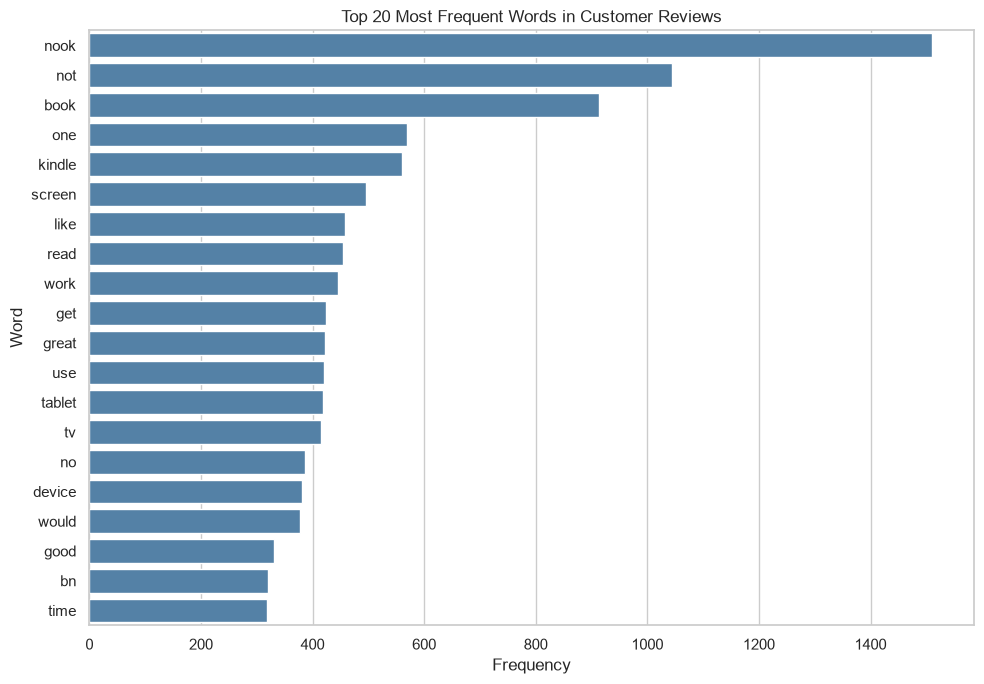

In [16]:
# 1.7. Word Frequency Analysis

# Purpose:
# Identify the words appearing most frequently
# across all customer reviews.


# 1. Combine tokens from all reviews
all_tokens = [
    token
    for document in df['processed_tokens']
    for token in document
]

# 2. Count how frequently each word appears
word_counts = Counter(all_tokens)

# 3. Identify the 20 most common words
top_20_words = word_counts.most_common(20)

# 4. Display results
print("Top 20 Most Common Words:")

for word, frequency in top_20_words:
    print(f"{word}: {frequency}")


# 1.8. Word Frequency Visualization


# 1. Convert frequency results into a DataFrame
word_freq_df = pd.DataFrame(
    top_20_words,
    columns=['Word', 'Frequency']
)

# 2. Create the visualization
plt.figure(figsize=(10, 7))

sns.barplot(
    data=word_freq_df,
    x='Frequency',
    y='Word',
    color='steelblue'
)

# 3. Add labels
plt.title('Top 20 Most Frequent Words in Customer Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')

# 4. Display the chart
plt.tight_layout()
plt.show()


Top 20 Most Common Bigrams:
barnes noble: 152
nook color: 127
battery life: 87
touch screen: 81
sd card: 80
nook hd: 74
work great: 63
nook tablet: 63
work well: 57
read book: 55
kindle fire: 55
wall mount: 51
no problem: 50
simple touch: 44
android tablet: 39
customer service: 38
nook simple: 37
bn store: 35
easy install: 34
original nook: 34


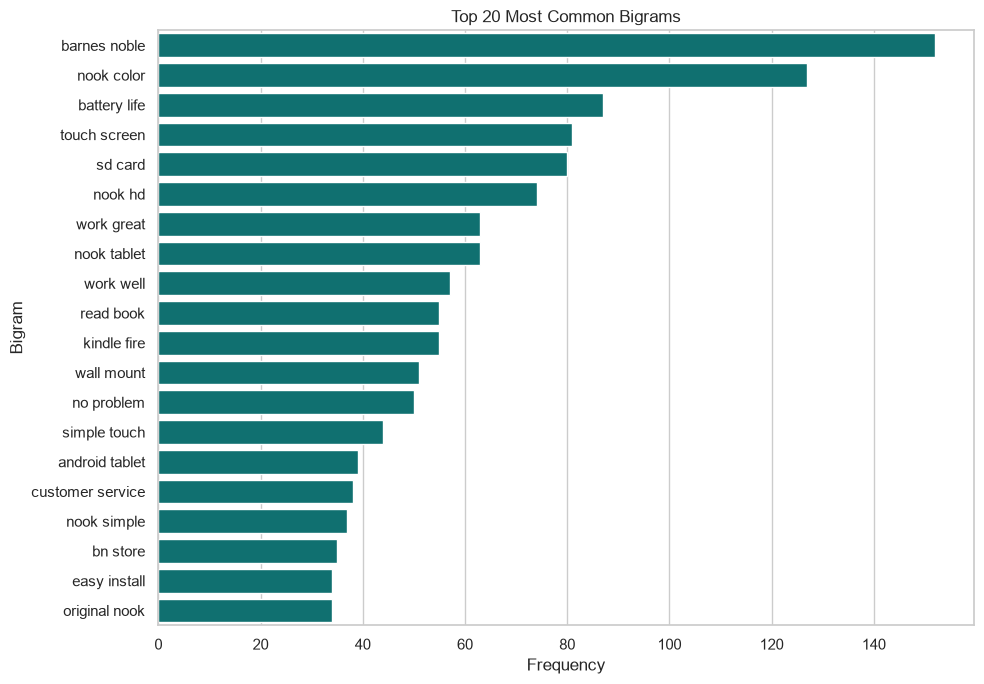

In [17]:
# 1.9. Bigram Frequency Analysis

# Purpose:
# Identify frequently occurring two-word combinations.


# 1. Generate bigrams within each individual review
all_bigrams = [
    bigram
    for tokens in df['processed_tokens']
    for bigram in ngrams(tokens, 2)
]

# 2. Count bigram frequencies
bigram_counts = Counter(all_bigrams)

# 3. Identify the 20 most common bigrams
top_20_bigrams = bigram_counts.most_common(20)

# 4. Display results
print("Top 20 Most Common Bigrams:")

for bigram, frequency in top_20_bigrams:
    print(f"{' '.join(bigram)}: {frequency}")


# 1.10. Bigram Frequency Visualization

# 1. Convert bigram results into a DataFrame
bigram_df = pd.DataFrame(
    [
        (' '.join(bigram), frequency)
        for bigram, frequency in top_20_bigrams
    ],
    columns=['Bigram', 'Frequency']
)

# 2. Create the visualization
plt.figure(figsize=(10, 7))

sns.barplot(
    data=bigram_df,
    x='Frequency',
    y='Bigram',
    color='teal'
)

# 3. Add descriptive labels
plt.title('Top 20 Most Common Bigrams')
plt.xlabel('Frequency')
plt.ylabel('Bigram')

# 4. Display the visualization
plt.tight_layout()
plt.show()

### Part 1: NLP – Observations and Findings

**1. Customer Rating Distribution**

The distribution of customer ratings is heavily skewed toward positive reviews, with 5-star ratings accounting for the largest proportion of observations. This suggests generally positive customer experiences. However, the imbalance may affect subsequent classification models by encouraging predictions toward the majority class

**2. Word Frequency Analysis**

The most frequent words include *nook*, *not*, *book*, *kindle*, and *screen*. This indicates that the dataset contains substantial discussion about electronic reading devices and their functionality. The frequent occurrence of negation words such as *not* and *no* highlights the importance of preserving contextual meaning during preprocessing

**3. Bigram Analysis**

Common bigrams such as *battery life*, *touch screen*, and *sd card* highlight frequently discussed product features. Meanwhile, phrases such as *work great*, *work well*, and *no problem* suggest positive customer experiences. These patterns provide useful insights into the aspects of products that customers frequently discuss

**4. Business Implications**

The findings suggest that businesses could benefit from monitoring customer feedback about product functionality, particularly battery performance, screen usability, and storage capabilities. Analyzing sentiment around these features could help identify areas for product improvement and customer support

**5. Limitations**

Word frequency and bigram analysis identify commonly discussed topics but do not establish whether customers feel positively or negatively about them. Furthermore, the imbalanced rating distribution may influence subsequent classification performance. More advanced sentiment analysis and class-specific evaluation would help address these limitations

**Conclusion**

The NLP analysis reveals a review collection dominated by positive ratings and discussions about electronic reading devices. Text preprocessing, word frequency analysis, and bigram extraction provide a useful foundation for understanding customer feedback and developing predictive models

### Part 2: Time Series 
This section will analyze activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings

In [19]:
# 2.1. Time Series Analysis

# 1. Load the dataset
df_ts = pd.read_csv('data/amazon_reviews_lab.csv')

# 2.2. Date and Time Preprocessing

# 1. Convert timestamp column to datetime
df_ts['timestamp'] = pd.to_datetime(
    df_ts['timestamp'],
    errors='coerce'
)

# 2. Check missing or invalid dates
print(
    "Missing Timestamps:",
    df_ts['timestamp'].isnull().sum()
)

# 3. Remove records without valid timestamps
df_ts = df_ts.dropna(subset=['timestamp']).copy()

# 4. Sort records chronologically
df_ts = df_ts.sort_values('timestamp')

# 5. Examine the earliest and latest dates
print("Earliest Review:", df_ts['timestamp'].min())
print("Latest Review:", df_ts['timestamp'].max())

# 6. Preview timestamps and ratings
display(df_ts[['timestamp', 'rating']].head())

Missing Timestamps: 0
Earliest Review: 2000-05-12 00:00:00
Latest Review: 2014-07-17 00:00:00


,timestamp,rating
0,2000-05-12,2
1,2002-08-26,5
2,2005-08-06,1
3,2005-09-11,1
4,2007-10-15,5


,Review_Count,Average_Rating
timestamp,,
2000-05-01,1,2.0
2000-06-01,0,NaN
2000-07-01,0,NaN
2000-08-01,0,NaN
2000-09-01,0,NaN
2000-10-01,0,NaN
2000-11-01,0,NaN
2000-12-01,0,NaN
2001-01-01,0,NaN


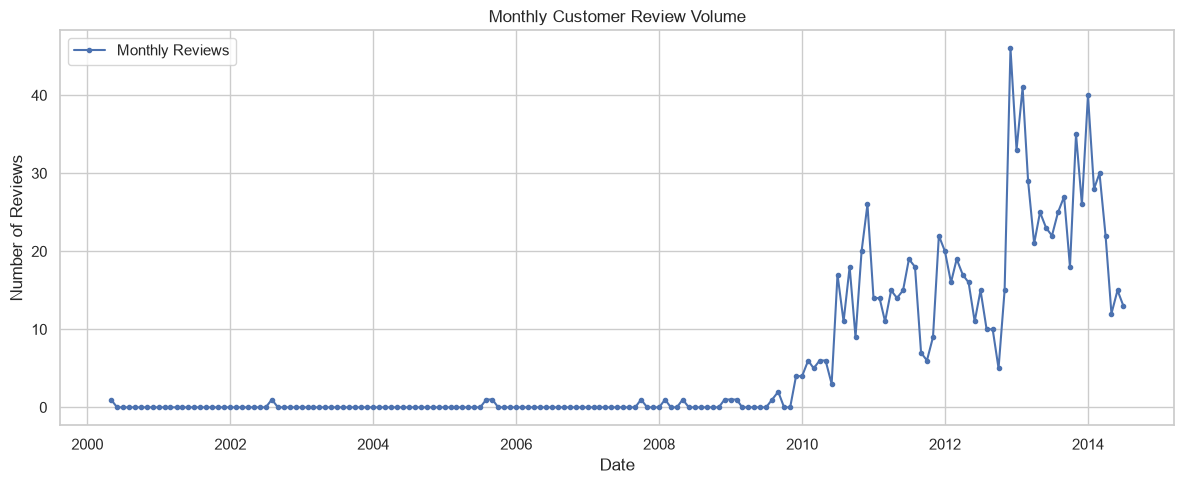

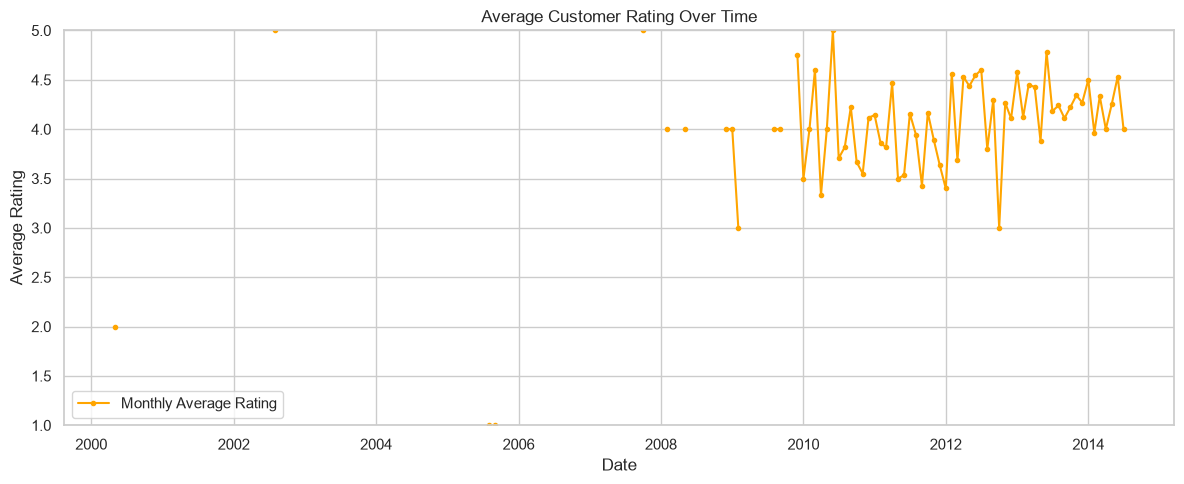

In [20]:
# 2.3. Monthly Data Aggregation

# 1. Set timestamp as the DataFrame index
df_ts = df_ts.set_index('timestamp')

# 2. Calculate monthly review counts
monthly_review_count = df_ts['rating'].resample('MS').count()

# 3. Calculate monthly average ratings
monthly_avg_rating = df_ts['rating'].resample('MS').mean()

# 4. Combine results into one DataFrame
monthly_summary = pd.DataFrame({
    'Review_Count': monthly_review_count,
    'Average_Rating': monthly_avg_rating
})

# 5. Display monthly summary
display(monthly_summary.head(12))


# 2.4. Monthly Review Volume Visualization

# 1. Create the figure
plt.figure(figsize=(12, 5))

# 2. Plot monthly review counts
plt.plot(
    monthly_review_count.index,
    monthly_review_count.values,
    marker='o',
    markersize=3,
    label='Monthly Reviews'
)

# 3. Add chart labels
plt.title('Monthly Customer Review Volume')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')

# 4. Display legend
plt.legend()

# 5. Display chart
plt.tight_layout()
plt.show()


# 2.5. Monthly Average Rating Visualization

# 1. Create the figure
plt.figure(figsize=(12, 5))

# 2. Plot monthly average ratings
plt.plot(
    monthly_avg_rating.index,
    monthly_avg_rating.values,
    color='orange',
    marker='o',
    markersize=3,
    label='Monthly Average Rating'
)

# 3. Add chart labels
plt.title('Average Customer Rating Over Time')
plt.xlabel('Date')
plt.ylabel('Average Rating')

# 4. Set rating scale
plt.ylim(1, 5)

# 5. Display legend
plt.legend()

# 6. Display chart
plt.tight_layout()
plt.show()

,Average_Rating,Rolling_Avg_3M
timestamp,,
2000-05-01,2.0,NaN
2000-06-01,NaN,NaN
2000-07-01,NaN,NaN
2000-08-01,NaN,NaN
2000-09-01,NaN,NaN
2000-10-01,NaN,NaN
2000-11-01,NaN,NaN
2000-12-01,NaN,NaN
2001-01-01,NaN,NaN


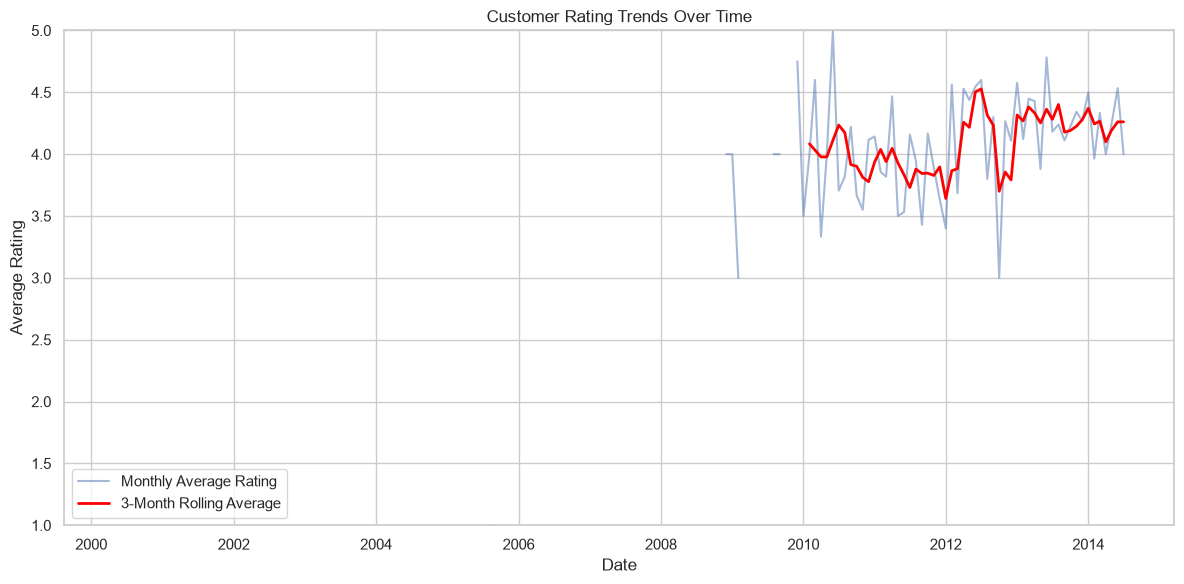

In [21]:
# 2.6 Rolling Average Calculation

# 1. Calculate a three-month rolling average
# Use at least three months before reporting a value
monthly_rolling_avg = monthly_avg_rating.rolling(
    window=3,
    min_periods=3
).mean()

# 2. Add rolling average to monthly summary
monthly_summary['Rolling_Avg_3M'] = monthly_rolling_avg

# 3. Display the results
display(
    monthly_summary[
        ['Average_Rating', 'Rolling_Avg_3M']
    ].head(12)
)


# 2.7 Original Ratings vs Rolling Average

# 1. Create figure
plt.figure(figsize=(12, 6))

# 2. Plot original monthly average ratings
plt.plot(
    monthly_avg_rating.index,
    monthly_avg_rating.values,
    label='Monthly Average Rating',
    alpha=0.5
)

# 3. Plot three-month rolling average
plt.plot(
    monthly_rolling_avg.index,
    monthly_rolling_avg.values,
    label='3-Month Rolling Average',
    color='red',
    linewidth=2
)

# 4. Add labels
plt.title('Customer Rating Trends Over Time')
plt.xlabel('Date')
plt.ylabel('Average Rating')

# 5. Set rating scale
plt.ylim(1, 5)

# 6. Display legend
plt.legend()

# 7. Display visualization
plt.tight_layout()
plt.show()

Months with Reviews: 55
Total Reviews: 980


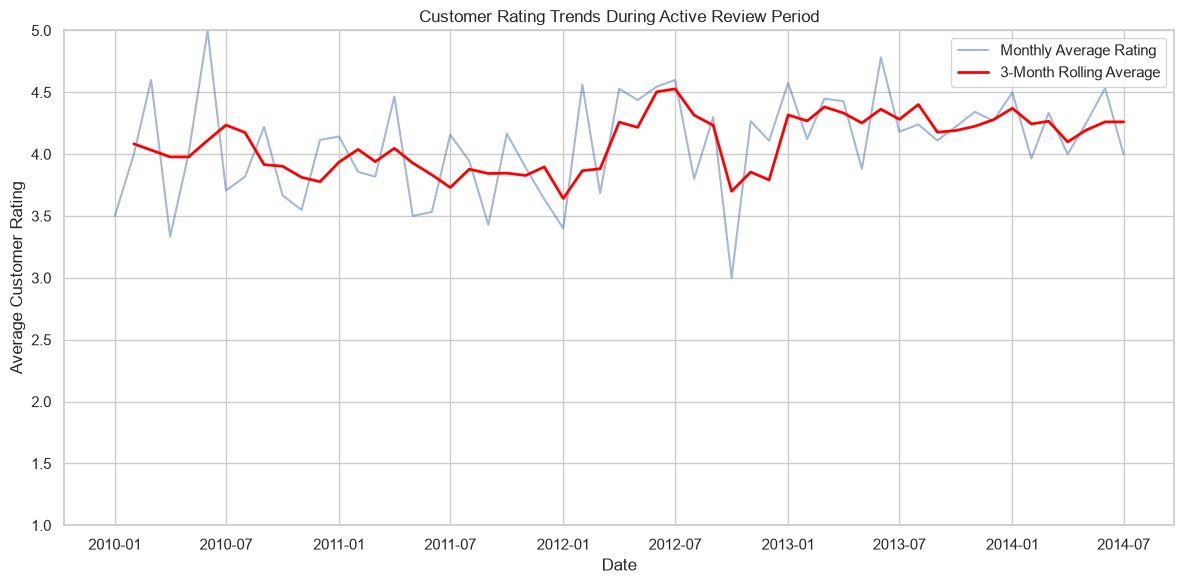

In [22]:
# 2.8 Focused Analysis - Active Review Period

# Purpose:
# Focus on the period with more consistent review activity
# to better understand customer rating trends.

# 1. Select data from 2010 onward
active_period = monthly_summary.loc['2010-01-01':].copy()

# 2. Calculate the number of months with reviews
months_with_reviews = (
    active_period['Review_Count'] > 0
).sum()

# 3. Calculate total reviews during this period
total_reviews = active_period['Review_Count'].sum()

# 4. Display summary
print("Months with Reviews:", months_with_reviews)
print("Total Reviews:", total_reviews)

# 5. Create figure
plt.figure(figsize=(12, 6))

# 6. Plot original monthly average ratings
plt.plot(
    active_period.index,
    active_period['Average_Rating'],
    label='Monthly Average Rating',
    alpha=0.5
)

# 7. Plot the rolling average
plt.plot(
    active_period.index,
    active_period['Rolling_Avg_3M'],
    label='3-Month Rolling Average',
    color='red',
    linewidth=2
)

# 8. Add labels
plt.title('Customer Rating Trends During Active Review Period')
plt.xlabel('Date')
plt.ylabel('Average Customer Rating')
plt.ylim(1, 5)

# 9. Display legend
plt.legend()

# 10. Display chart
plt.tight_layout()
plt.show()

### Part 2: Time Series Analysis – Observations and Findings

**1. Monthly Review Volume**

The time series analysis reveals a substantial increase in customer review activity over the observed period. Between 2000 and 2009, review activity was extremely limited, with most months recording no reviews. However, from 2010 onward, review volume increased considerably, reaching its highest levels during 2013–2014

This indicates that the later years are more representative of customer review activity within the dataset

**2. Average Customer Ratings**

Average customer ratings remained generally positive during the period of increased review activity, frequently ranging between 3.5 and 4.5 stars. However, occasional declines suggest variations in customer experiences

Earlier observations are less reliable because very few reviews were recorded during those years

**3. Three-Month Rolling Average**

The three-month rolling average reduced short-term fluctuations and provided a clearer representation of customer rating trends. The smoothed series suggests that average ratings remained relatively stable and generally favorable during the more active review period, with some periods of improvement and temporary decline

**4. Missing Values and Data Limitations**

Several months, particularly before 2010, contain no customer reviews, resulting in missing average ratings. These missing values reflect an absence of observations rather than zero customer satisfaction

The limited number of reviews in earlier years restricts the reliability of long-term comparisons. Additionally, fluctuations in months with few reviews may not reflect broader changes in customer satisfaction

**5. Business Implications**

The analysis demonstrates how businesses can monitor customer feedback over time to identify changes in review activity and satisfaction

Tracking monthly review volumes alongside average ratings could help identify periods requiring further investigation. Rolling averages can also help distinguish short-term fluctuations from more persistent changes in customer experiences

**Conclusion**

The time series analysis indicates that customer review activity increased substantially after 2010, while average customer ratings remained generally favorable. The three-month rolling average provided a clearer view of rating trends, although missing observations and uneven review volumes should be considered when interpreting the findings

### Part 3: Neural Networks

This section will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance

In [23]:
# 3.1. Import required libraries for machine learning

# 1 Import preprocessing tools
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 2. Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 3. Import TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 4. Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

In [24]:
# 3.2. Data Loading and Preparation

# 1. Load dataset
df_nn = pd.read_csv('data/amazon_reviews_lab.csv')

# 2. Remove rows with missing review text or ratings
df_nn = df_nn.dropna(
    subset=['review_text', 'rating']
).copy()

# 3. Remove empty reviews
df_nn = df_nn[
    df_nn['review_text'].str.strip() != ''
].copy()

# 4. Define input features
X = df_nn['review_text'].astype(str)

# 5. Define target labels
# Ratings 1-5 become classes 0-4
y = df_nn['rating'].astype(int) - 1

# 6. Check rating distribution
print("Target Class Distribution:")
print(y.value_counts().sort_index())

# 7. Display dataset size
print("\nNumber of Reviews:", len(X))

Target Class Distribution:
rating
0     87
1     48
2     94
3    188
4    580
Name: count, dtype: int64

Number of Reviews: 997


In [25]:
# 3.3 Train-Test Split

# 1. Split data into 80% training and 20% testing
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 2. Display split sizes
print("Training Samples:", len(X_train_text))
print("Testing Samples:", len(X_test_text))

Training Samples: 797
Testing Samples: 200


In [26]:
# 3.4. TF-IDF Text Vectorization

# 1. Initialize TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    max_features=2000,
    stop_words='english',
    ngram_range=(1, 2)
)

# 2. Learn vocabulary from training data only
X_train_tfidf = vectorizer.fit_transform(X_train_text)

# 3. Transform test data using the fitted vectorizer
X_test_tfidf = vectorizer.transform(X_test_text)

# 4. Convert sparse matrices to dense arrays
X_train_nn = X_train_tfidf.toarray().astype('float32')
X_test_nn = X_test_tfidf.toarray().astype('float32')

# 5. Display feature dimensions
print("Training Shape:", X_train_nn.shape)
print("Testing Shape:", X_test_nn.shape)

# 6. Display number of selected features
print("Number of Features:", len(vectorizer.get_feature_names_out()))

Training Shape: (797, 2000)
Testing Shape: (200, 2000)
Number of Features: 2000
